# Alzheimer MRI Classification with Vision Transformer (ViT)

This notebook uses a safer ViT pipeline with:
- duplicate-aware train/validation splitting
- repeated-slice audit on the test set
- patient-group evaluation inferred from filenames
- only the most useful plots for model review


In [15]:
import importlib

import vit_alzheimer_pipeline as pipeline

pipeline = importlib.reload(pipeline)

TrainingConfig = pipeline.TrainingConfig
plot_dataset_distribution = pipeline.plot_dataset_distribution
plot_training_curves = pipeline.plot_training_curves
print_test_metrics = pipeline.print_test_metrics
print_classification_report = pipeline.print_classification_report
plot_per_class_metrics = pipeline.plot_per_class_metrics
plot_confusion_matrix_from_results = pipeline.plot_confusion_matrix_from_results
plot_roc_curves_from_results = pipeline.plot_roc_curves_from_results
plot_precision_recall_curves_from_results = pipeline.plot_precision_recall_curves_from_results
refresh_test_evaluation = pipeline.refresh_test_evaluation
run_experiment = pipeline.run_experiment

In [16]:
config = TrainingConfig(
    model_name="vit_tiny_patch16_224",
    img_size=224,
    batch_size=8,
    epochs=15,
    val_size=0.15,
    backbone_lr=2e-5,
    head_lr=1e-4,
    weight_decay=1e-4,
    label_smoothing=0.08,
    drop_rate=0.2,
    drop_path_rate=0.2,
    random_erasing_prob=0.15,
    use_weighted_sampler=True,
    sampler_power=0.5,
    class_weight_power=0.5,
    freeze_backbone_epochs=1,
    gradient_clip_norm=1.0,
    early_stopping_patience=5,
    reduce_lr_patience=2,
    split_by_hash_groups=True,
    deduplicate_train=True,
    audit_dataset=True,
    seed=42,
)

config

TrainingConfig(train_dir='Dataset/Training Set', test_dir='Dataset/Testing Set', model_name='vit_tiny_patch16_224', img_size=224, batch_size=8, epochs=15, val_size=0.15, backbone_lr=2e-05, head_lr=0.0001, weight_decay=0.0001, label_smoothing=0.08, drop_rate=0.2, drop_path_rate=0.2, random_erasing_prob=0.15, use_weighted_sampler=True, sampler_power=0.5, class_weight_power=0.5, freeze_backbone_epochs=1, gradient_clip_norm=1.0, early_stopping_patience=5, reduce_lr_patience=2, split_by_hash_groups=True, deduplicate_train=True, audit_dataset=True, seed=42, num_workers=0)

## Train and Evaluate

Run the next cell to train the ViT model, restore the best checkpoint, and evaluate on the test set.

If you already trained and only want to recompute the test evaluation after changing the pipeline, use:

```python
results = refresh_test_evaluation(results)
test_results = results["test_results"]
```

In [17]:
results = run_experiment(config)
test_results = results["test_results"]

Using device: cuda
Config:
  train_dir: Dataset/Training Set
  test_dir: Dataset/Testing Set
  model_name: vit_tiny_patch16_224
  img_size: 224
  batch_size: 8
  epochs: 15
  val_size: 0.15
  backbone_lr: 2e-05
  head_lr: 0.0001
  weight_decay: 0.0001
  label_smoothing: 0.08
  drop_rate: 0.2
  drop_path_rate: 0.2
  random_erasing_prob: 0.15
  use_weighted_sampler: True
  sampler_power: 0.5
  class_weight_power: 0.5
  freeze_backbone_epochs: 1
  gradient_clip_norm: 1.0
  early_stopping_patience: 5
  reduce_lr_patience: 2
  split_by_hash_groups: True
  deduplicate_train: True
  audit_dataset: True
  seed: 42
  num_workers: 0


Class distribution
------------------------------------------------------------
Class                   Train      Val     Test
------------------------------------------------------------
MildDemented             7506     1324      896
ModerateDemented         5227      922       64
NonDemented              8146     1438     3200
VeryMildDemented         7602     1341     2240
------------------------------------------------------------
Dataset audit
------------------------------------------------------------
Train duplicate groups: 195
Redundant duplicate train files: 462
Cross-class duplicate groups: 0
Exact train/val hash overlap after split: 0
Exact train/test hash overlap: 0
Train samples used after split: 28481
Validation samples used after split: 5025
------------------------------------------------------------
Test patient-group audit (inferred from filename)
------------------------------------------------------------
Class                  Images   Patients   Repeat   Mean/

Model loaded successfully
Backbone parameters: 5,524,416
Head parameters: 772
Backbone frozen for the first 1 epoch(s).


Epoch 01/15 | train_loss=1.4741 | train_acc=0.2815 | val_loss=1.3345 | val_acc=0.3930 | val_macro_f1=0.3340 | val_macro_auc=0.6840
Backbone unfrozen. Fine-tuning the full network.


Epoch 02/15 | train_loss=1.0244 | train_acc=0.5592 | val_loss=0.8442 | val_acc=0.6722 | val_macro_f1=0.6989 | val_macro_auc=0.8878


...

Epoch 11/15 | train_loss=0.5039 | train_acc=0.9024 | val_loss=0.4091 | val_acc=0.9491 | val_macro_f1=0.9536 | val_macro_auc=0.9953


Epoch 12/15 | train_loss=0.4896 | train_acc=0.9110 | val_loss=0.4003 | val_acc=0.9578 | val_macro_f1=0.9613 | val_macro_auc=0.9955


Epoch 13/15 | train_loss=0.4827 | train_acc=0.9157 | val_loss=0.4107 | val_acc=0.9550 | val_macro_f1=0.9591 | val_macro_auc=0.9957


Epoch 14/15 | train_loss=0.4749 | train_acc=0.9205 | val_loss=0.3832 | val_acc=0.9668 | val_macro_f1=0.9697 | val_macro_auc=0.9972


Epoch 15/15 | train_loss=0.4595 | train_acc=0.9302 | val_loss=0.3801 | val_acc=0.9705 | val_macro_f1=0.9731 | val_macro_auc=0.9972
Best checkpoint restored from epoch 15.


## Dataset Distribution

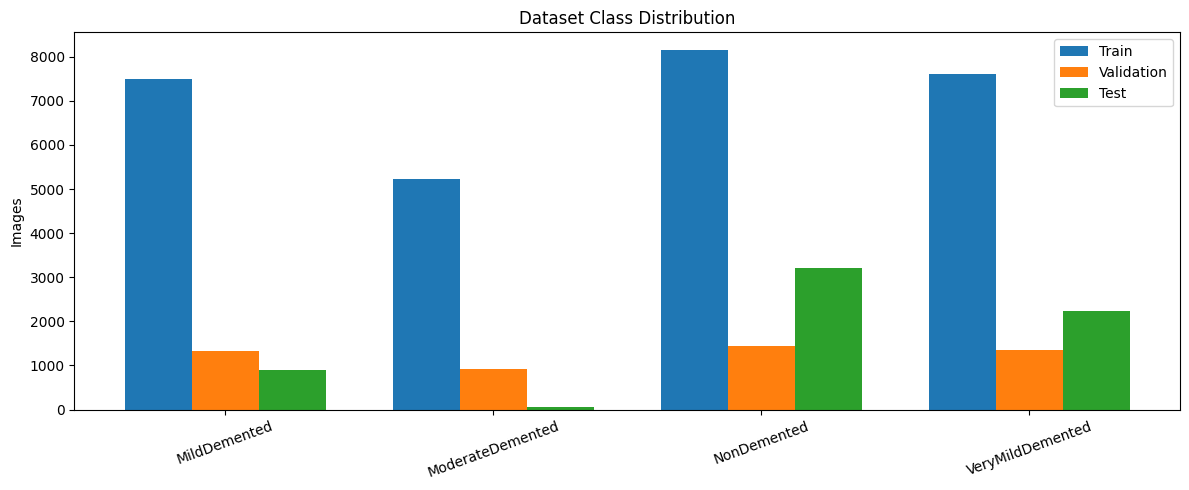

In [18]:
plot_dataset_distribution(
    results["class_names"],
    results["train_counts"],
    results["val_counts"],
    results["test_counts"],
)

## Training Curves

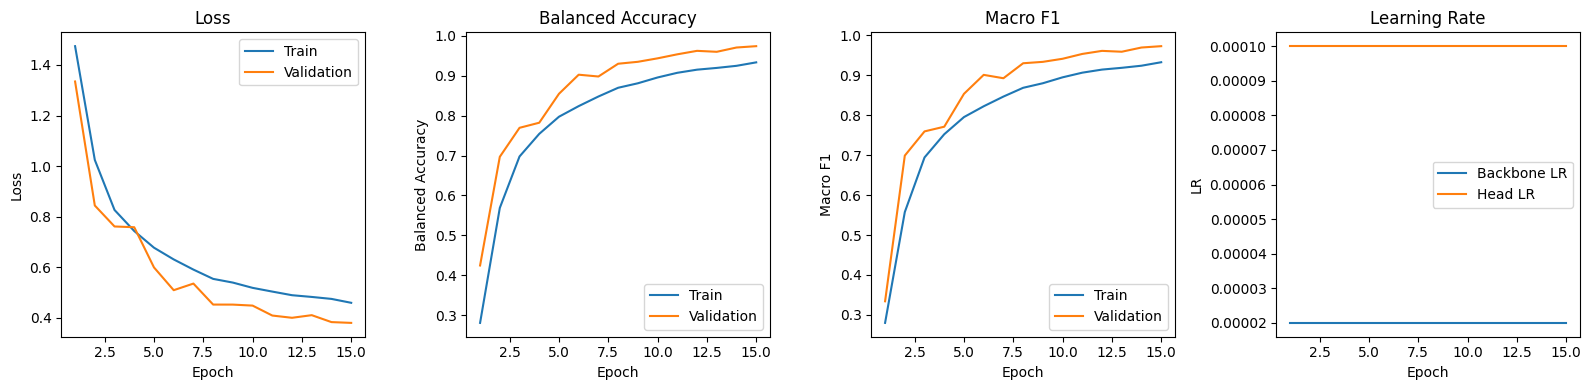

In [19]:
plot_training_curves(results["history"])

## Test Metrics

In [20]:
print(f"Best validation selection score: {results['best_score']:.4f} (epoch {results['best_epoch']})")
print_test_metrics(test_results)
print_classification_report(test_results)

Best validation selection score: 0.9803 (epoch 15)
Image-level test metrics
Test loss: 0.2014
Accuracy: 0.9508
Balanced accuracy: 0.9703
Macro F1: 0.9599
Weighted F1: 0.9510
Macro precision: 0.9512
Macro recall: 0.9703
Macro ROC-AUC (OvR): 0.9938
Macro Average Precision: 0.9903

Patient-level test metrics (slice probabilities averaged per inferred patient)
Patients evaluated: 5148
Multi-slice patients: 27
Max slices for one patient: 100
Inconsistent label groups: 0
Accuracy: 0.9518
Balanced accuracy: 0.9711
Macro F1: 0.9600
Weighted F1: 0.9521
Macro precision: 0.9509
Macro recall: 0.9711
Macro ROC-AUC (OvR): 0.9935
Macro Average Precision: 0.9901
Image-level classification report
                  precision    recall  f1-score   support

    MildDemented       0.89      0.99      0.94       896
ModerateDemented       1.00      1.00      1.00        64
     NonDemented       0.98      0.94      0.96      3200
VeryMildDemented       0.93      0.95      0.94      2240

        accuracy   

## Per-Class Metrics

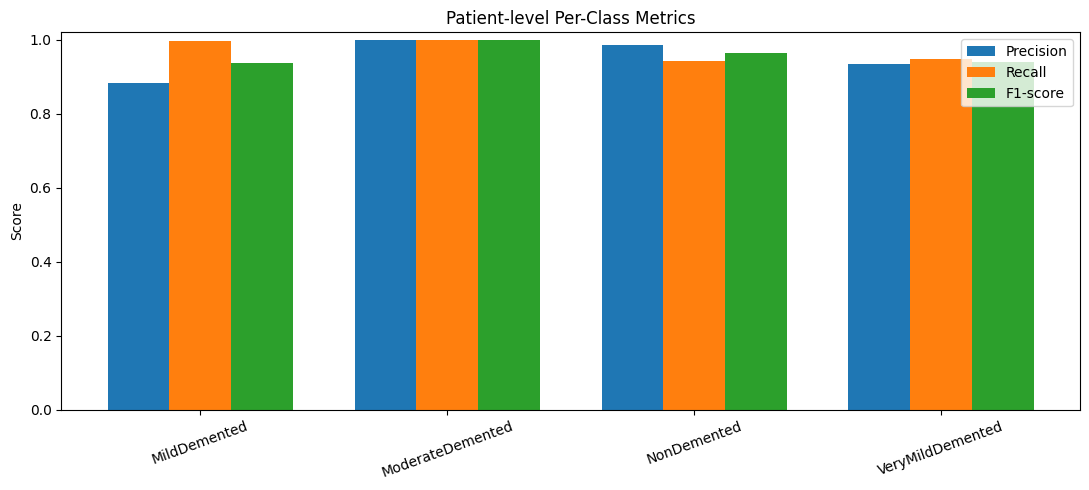

In [21]:
plot_per_class_metrics(test_results, results["class_names"], level="patient")

## Confusion Matrices

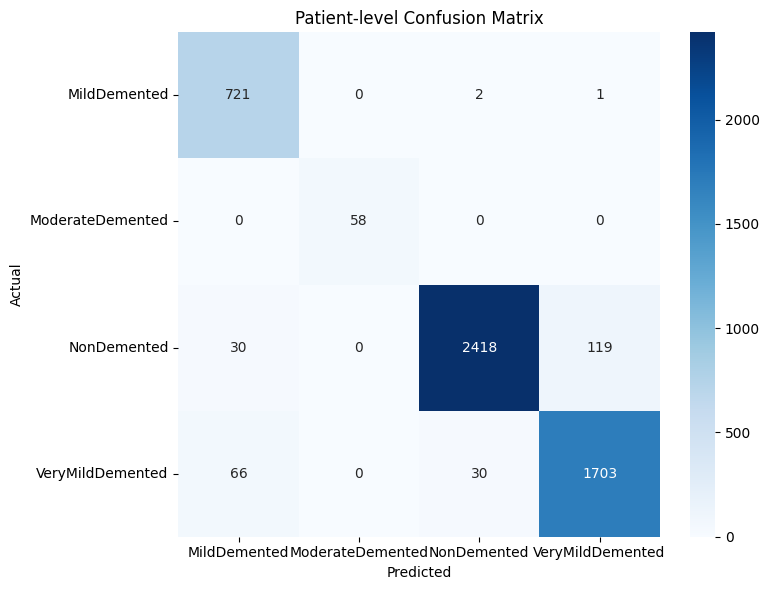

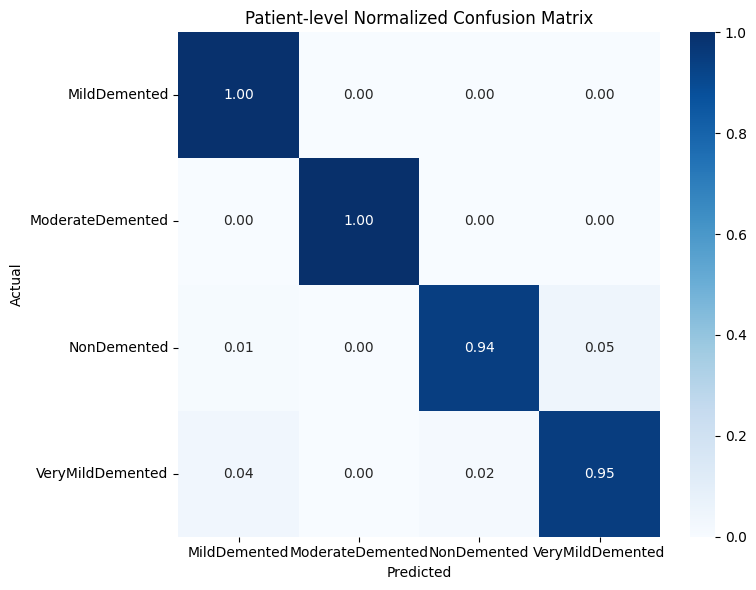

In [22]:
plot_confusion_matrix_from_results(test_results, results["class_names"], normalize=False, level="patient")
plot_confusion_matrix_from_results(test_results, results["class_names"], normalize=True, level="patient")

## ROC Curves

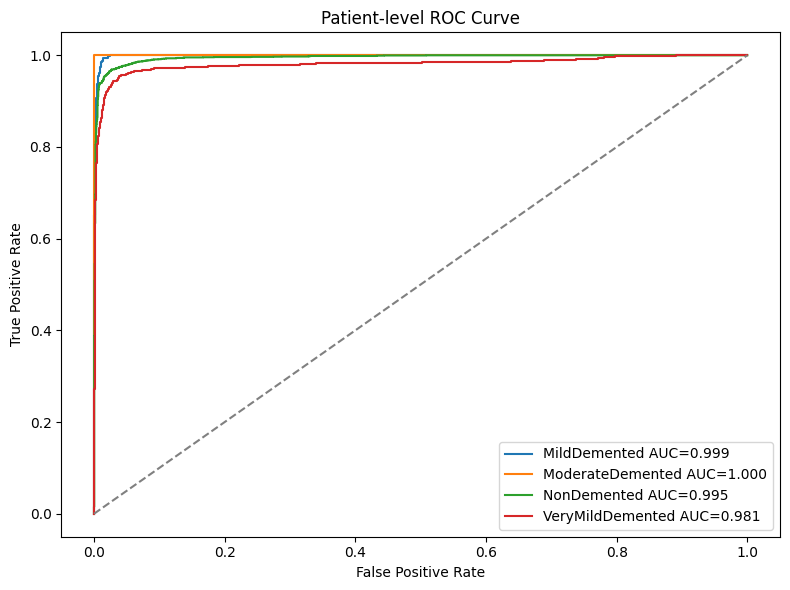

{'per_class_auc': {0: 0.998579446115113,
  1: 1.0,
  2: 0.9947169442814779,
  3: 0.9807459138823517},
 'macro_auc': 0.9935105760697357,
 'level': 'Patient-level'}

In [23]:
roc_summary = plot_roc_curves_from_results(test_results, results["class_names"], level="patient")
roc_summary

## Precision-Recall Curves

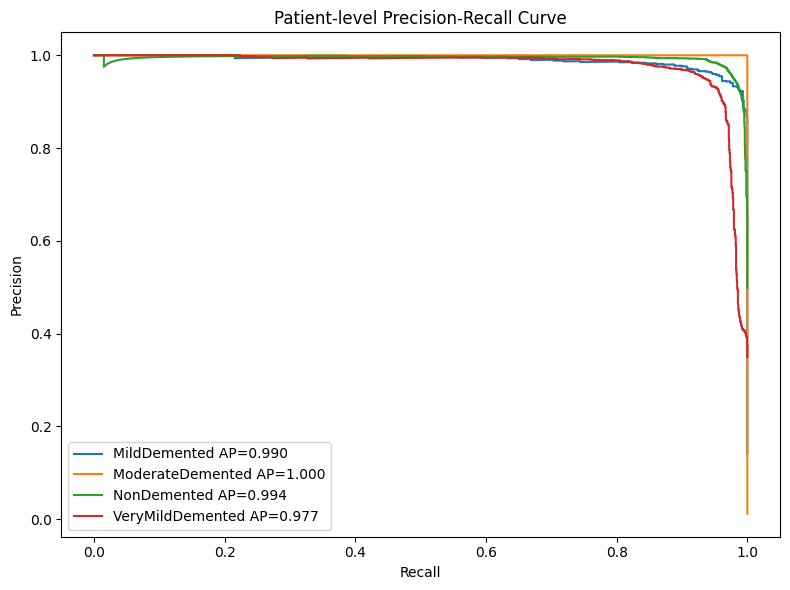

{'per_class_average_precision': {0: 0.989748848857089,
  1: 1.0000000000000002,
  2: 0.9935990362195662,
  3: 0.9769618248566112},
 'macro_average_precision': 0.9900774274833166,
 'level': 'Patient-level'}

In [24]:
pr_summary = plot_precision_recall_curves_from_results(test_results, results["class_names"], level="patient")
pr_summary